In [29]:
import numpy as np
import pandas as pd

#models ml tools 
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.preprocessing import LabelEncoder

from pathlib import Path


from econml.dml import LinearDML, CausalForestDML
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier


import matplotlib.pyplot as plt
import seaborn as sns


In [30]:
from pathlib import Path
import joblib

DATA_DIR = Path(
    r"E:\internhips\infotact solutions\Dynamic Pricing via Double Machine Learning\backend\data\processed"
)

X = joblib.load(DATA_DIR / "X.pkl")
T = joblib.load(DATA_DIR / "T.pkl")
Y = joblib.load(DATA_DIR / "Y.pkl")



# Split into training and testing sets
X_train, X_test, T_train, T_test, Y_train, Y_test = train_test_split(
    X,
    T,
    Y,
    test_size=0.2,
    random_state=42
)


# Model Training


m1 : y[conversion] - will customer purchase

How much receiving an email affects conversion
after removing confounding effects.

m 2: y[spend] - how much an extra revenue email Generates 

# -------------------------
# creating base model

In [31]:
model_y = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42
)

model_t = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42
)


In [32]:
print(Y_train.dtype)
print(T_train.dtype)

print(Y_train.unique()[:10])
print(T_train.unique()[:10])


print(X_train.dtypes)

int64
int64
[0 1]
[1 0]
recency       int64
history     float64
mens          int64
womens        int64
zip_code      int64
newbie        int64
channel       int64
dtype: object


In [33]:
# so here combine both model using dml 

dml = CausalForestDML(
    model_y=model_y,
    model_t=model_t,
    n_estimators=200,
    random_state=42
)


In [34]:
dml.fit(
    Y_train,
    T_train,
    X=X_train
)

# predict indivdual tratment effect

In [35]:
ite = dml.effect(X_test)

print(ite[:5])

[0.00535912 0.00528643 0.00442323 0.02832036 0.00470211]


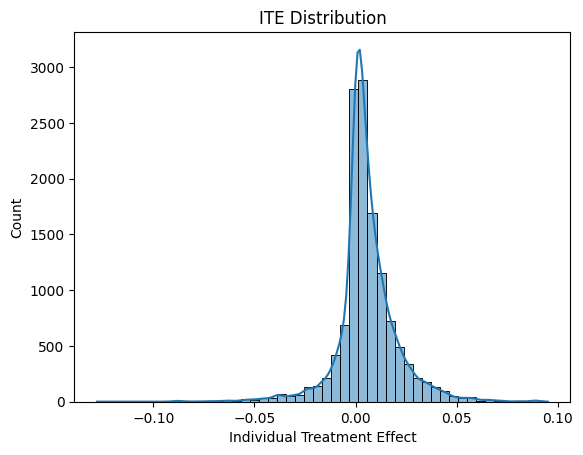

In [36]:
sns.histplot(
    ite,
    bins=50,
    kde=True
)

plt.title("ITE Distribution")
plt.xlabel("Individual Treatment Effect")
plt.show()

In [37]:
print("Min ITE:", ite.min())
print("Max ITE:", ite.max())
print("Mean ITE:", ite.mean())

Min ITE: -0.12791142509922837
Max ITE: 0.09510350690540545
Mean ITE: 0.005564630628399456


In [38]:
results = X_test.copy()

results["ITE"] = ite

top_customers = results.sort_values(
    "ITE",
    ascending=False
)

print(top_customers.head(20))

       recency  history  mens  womens  zip_code  newbie  channel       ITE
14784        1  1500.19     1       1         1       1        0  0.095104
45882        1    29.99     1       0         0       1        1  0.089655
41253        1    29.99     1       0         0       1        1  0.089655
16591        1    29.99     1       0         0       1        1  0.089655
270          1    29.99     1       0         0       1        1  0.089655
40466        1    29.99     1       0         0       1        1  0.089655
12584        4    29.99     1       0         2       0        2  0.088402
3861         4    29.99     1       0         2       0        2  0.088402
2359         4    29.99     1       0         2       0        2  0.088402
38094        4    29.99     1       0         2       0        2  0.088402
10206        4    29.99     1       0         2       0        2  0.088402
17521        4    29.99     1       0         2       0        2  0.088402
22133        4    29.99  

In [39]:
results["segment"] = "Low"

results.loc[
    results["ITE"] > 0.02,
    "segment"
] = "High"

results.loc[
    (results["ITE"] > 0.01)
    &
    (results["ITE"] <= 0.02),
    "segment"
] = "Medium"

print(results["segment"])
print(results["segment"].unique())
# print(results["segment"].unique().count)

33042     Low
7209      Low
24367     Low
19599    High
31465     Low
         ... 
29518    High
40886     Low
19792     Low
31101     Low
54307     Low
Name: segment, Length: 12800, dtype: object
['Low' 'High' 'Medium']


In [40]:
print(results["segment"].value_counts())

segment
Low       9192
Medium    2083
High      1525
Name: count, dtype: int64


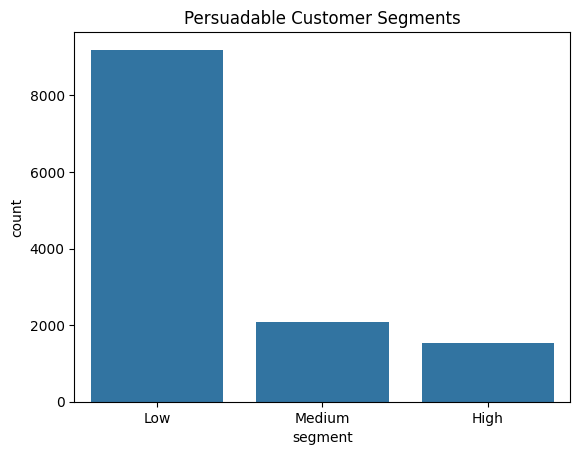

In [41]:
sns.countplot(
    data=results,
    x="segment",
    order=["Low", "Medium", "High"]
)

plt.title("Persuadable Customer Segments")
plt.show()

In [42]:
top_customers = results.sort_values(
    "ITE",
    ascending=False
)

print(top_customers.head(20))

       recency  history  mens  womens  zip_code  newbie  channel       ITE  \
14784        1  1500.19     1       1         1       1        0  0.095104   
45882        1    29.99     1       0         0       1        1  0.089655   
41253        1    29.99     1       0         0       1        1  0.089655   
16591        1    29.99     1       0         0       1        1  0.089655   
270          1    29.99     1       0         0       1        1  0.089655   
40466        1    29.99     1       0         0       1        1  0.089655   
12584        4    29.99     1       0         2       0        2  0.088402   
3861         4    29.99     1       0         2       0        2  0.088402   
2359         4    29.99     1       0         2       0        2  0.088402   
38094        4    29.99     1       0         2       0        2  0.088402   
10206        4    29.99     1       0         2       0        2  0.088402   
17521        4    29.99     1       0         2       0        2

In [43]:
profit_per_conversion = 20

results["expected_revenue"] = (
    results["ITE"] *
    profit_per_conversion
)

In [44]:
results["discount"] = 0

results.loc[
    results["segment"]=="High",
    "discount"
] = 20

results.loc[
    results["segment"]=="Medium",
    "discount"
] = 10

results

,recency,history,mens,womens,zip_code,newbie,channel,ITE,segment,expected_revenue,discount
33042,9,64.85,1,0,1,1,2,0.005359,Low,0.107182,0
7209,1,144.12,0,1,2,0,2,0.005286,Low,0.105729,0
24367,1,734.25,0,1,1,1,1,0.004423,Low,0.088465,0
19599,4,1321.26,1,0,1,1,0,0.028320,High,0.566407,20
31465,2,261.23,1,1,1,1,2,0.004702,Low,0.094042,0
...,...,...,...,...,...,...,...,...,...,...,...
29518,10,29.99,0,1,1,0,2,0.025392,High,0.507841,20
40886,10,197.14,0,1,2,1,1,0.006996,Low,0.139913,0
19792,6,110.77,1,0,1,0,2,0.000006,Low,0.000123,0
31101,2,51.78,0,1,0,0,1,0.009068,Low,0.181364,0


In [45]:
results["cost"] = results["discount"]
print(
    results["cost"].sum()
)

51330


In [46]:
final_targets = (
    results
    .sort_values(
        "ITE",
        ascending=False
    )
)

results.to_csv(
    "customer_recommendations.csv",
    index=False
)